### 1. Импорт библиотек и первичный анализ данных (EDA)

В соответствии с первым требованием лабораторной работы, мы загружаем датасет для бинарной классификации. Цель — предсказать наличие сердечного заболевания (`heart_disease`, где 1 — болезнь есть, 0 — нет).

На данном этапе мы:
* Импортируем необходимые библиотеки.
* Проверяем размерность данных, типы признаков и наличие пропусков.
* Изучаем распределение целевой переменной. Важно убедиться, что классы сбалансированы, чтобы метрики качества в будущем были объективными.

Mounted at /content/drive
Первые 5 строк:


,full_name,age,country,state,blood_pressure,cholesterol,bmi,glucose_level,gender,first_name,last_name,hospital,treatment,treatment_date,heart_disease
0,Alice Johnson,21,USA,Utah,138.068129,270.564349,36.101427,63.487954,Female,Alice,Johnson,Starlight Hospital,Physiotherapy,2021-07-07 21:23:23.542872956,1
1,Bob Williams,44,USA,North Dakota,100.383639,160.910030,14.330471,187.008977,Female,Bob,Williams,Maple Leaf Hospital,Counseling,2023-09-13 07:31:37.167014532,0
2,Oliver Jones,22,USA,Iowa,145.618318,208.490251,20.277098,35.903576,Female,Oliver,Jones,Crossroads Health Center,Medication,2019-11-22 03:56:29.389793943,0
3,Quinn Davis,19,USA,Louisiana,152.577870,348.153738,62.712693,31.495166,Female,Quinn,Davis,Springfield General Hospital,Counseling,2021-10-09 23:10:16.253672680,1
4,Alice Martinez,64,USA,Massachusetts,111.793570,200.628925,14.468485,154.513129,Female,Alice,Martinez,Valley View Hospital,Rehabilitation,2018-03-16 04:43:59.950843739,1



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   full_name       10000 non-null  object 
 1   age             10000 non-null  int64  
 2   country         10000 non-null  object 
 3   state           10000 non-null  object 
 4   blood_pressure  10000 non-null  float64
 5   cholesterol     10000 non-null  float64
 6   bmi             10000 non-null  float64
 7   glucose_level   10000 non-null  float64
 8   gender          10000 non-null  object 
 9   first_name      10000 non-null  object 
 10  last_name       10000 non-null  object 
 11  hospital        10000 non-null  object 
 12  treatment       10000 non-null  object 
 13  treatment_date  10000 non-null  object 
 14  heart_disease   10000 non-null  int64  
dtypes: float64(4), int64(2), object(9)
memory usage: 1.1+ MB

Пропуски:
full_name         0
age         

,age,blood_pressure,cholesterol,bmi,glucose_level,heart_disease
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,48.566700,104.837432,206.309340,21.418244,90.239345,0.500700
std,17.962461,33.437049,95.123826,13.011348,91.885699,0.500025
min,18.000000,10.459711,0.183391,0.011695,-185.805248,0.000000
25%,33.000000,81.304705,131.375908,10.898010,13.776164,0.000000
50%,49.000000,97.742674,213.826294,21.057592,88.909937,1.000000
75%,64.000000,124.318920,279.348476,28.836712,164.695370,1.000000
max,79.000000,244.542017,539.094051,75.308643,377.564242,1.000000



Распределение целевой переменной heart_disease:
heart_disease
1    5007
0    4993
Name: count, dtype: int64


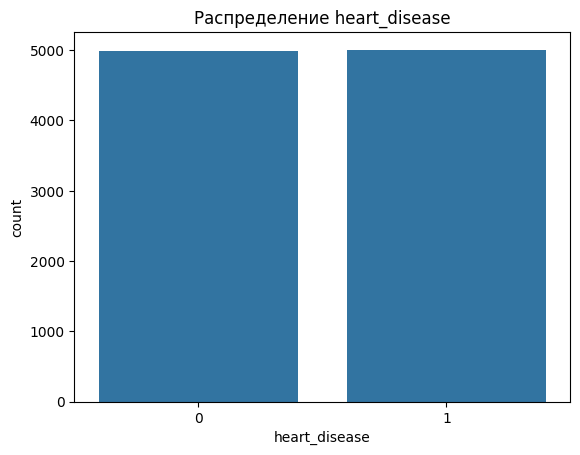

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')


DATA_PATH = Path(
    "/content/drive/MyDrive/colab_data/Heart_Disease_and_Hospitals.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH}\n"
        "Проверьте, что Heart_Disease_and_Hospitals.csv "
        "находится в папке MyDrive/colab_data/"
    )

df = pd.read_csv(DATA_PATH)

# Просмотр первых строк
print("Первые 5 строк:")
display(df.head())

# Информация о данных
print("\nИнформация о данных:")
df.info()

# Проверка пропусков
print("\nПропуски:")
print(df.isnull().sum())

# Описание числовых признаков
print("\nОписание числовых признаков:")
display(df.describe())

# Распределение целевой переменной
print("\nРаспределение целевой переменной heart_disease:")
print(df['heart_disease'].value_counts())
sns.countplot(x='heart_disease', data=df)
plt.title('Распределение heart_disease')
plt.show()

###2. Исследование категориальных признаков и первичный поиск аномалий

На этом этапе мы анализируем текстовые признаки:
* Некоторые из них (например, `country` или имена) не несут полезной информации.
* Другие (например, `hospital`, `state`) имеют слишком высокую кардинальность (много уникальных значений), что может привести к переобучению модели.

С помощью ящиков с усами (`boxplot`) и поиска экстремальных значений мы выявляем аномалии в числовых признаках. Мы видим, что уровень глюкозы и холестерина имеют физиологически невозможные значения (например, отрицательные числа), которые необходимо исправить.


--- country ---
Уникальных значений: 1
country
USA    10000
Name: count, dtype: int64

--- state ---
Уникальных значений: 50
state
Michigan         240
Oregon           228
New Mexico       226
Mississippi      224
Connecticut      224
New Hampshire    214
Hawaii           212
Massachusetts    212
Maryland         212
North Dakota     211
Name: count, dtype: int64

--- gender ---
Уникальных значений: 2
gender
Male      5082
Female    4918
Name: count, dtype: int64

--- hospital ---
Уникальных значений: 49
hospital
Forest View Hospital          936
Southgate Medical Facility    817
Sunset Valley Hospital        757
Summit View Hospital          741
Starlight Hospital            737
Hilltop Health Center         514
Aspen Grove Medical Center    366
Mountainview Hospital         360
Central City Hospital         348
Valley View Hospital          343
Name: count, dtype: int64

--- treatment ---
Уникальных значений: 5
treatment
Counseling        2084
Medication        2011
Surgery        

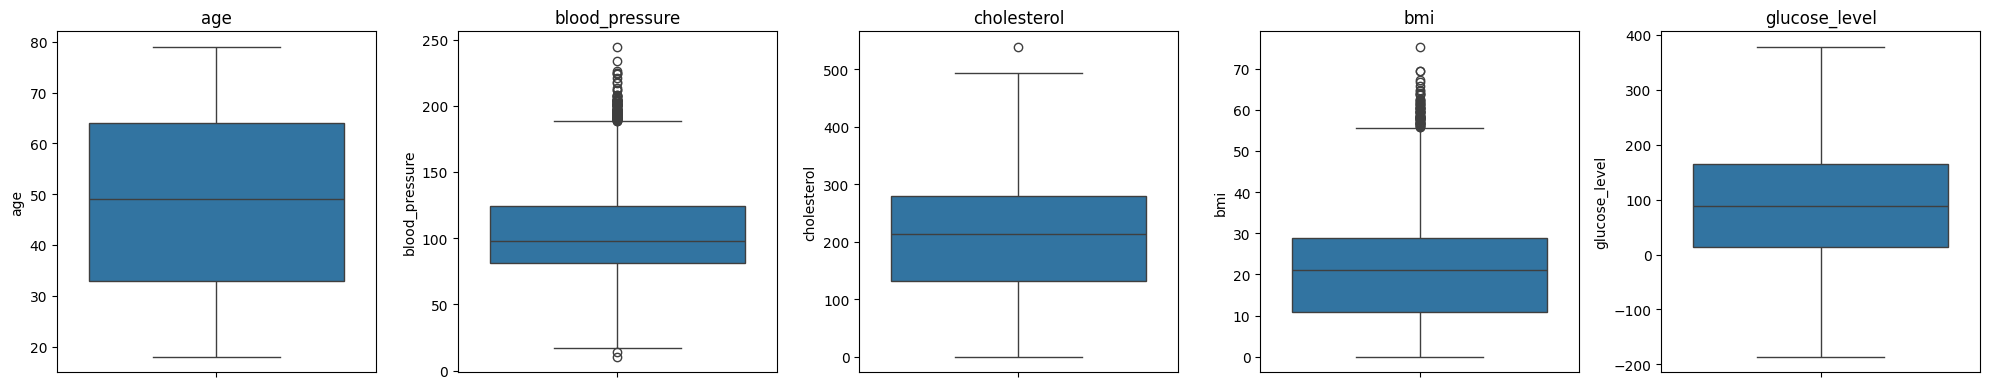


Самые низкие glucose_level:


,glucose_level,heart_disease
5616,-185.805248,0
9353,-167.989714,0
2181,-145.774625,0
4220,-145.594319,0
1530,-139.834752,1



Самые высокие glucose_level:


,glucose_level,heart_disease
930,377.564242,0
7047,354.164805,0
760,347.198617,0
6244,345.825672,0
99,341.467043,0



Самые низкие cholesterol:


,cholesterol,heart_disease
1831,0.183391,0
7880,0.513196,0
6854,0.593475,1
243,0.763456,1
8037,1.252851,1



Самые высокие cholesterol:


,cholesterol,heart_disease
975,539.094051,1
4340,494.235321,1
9698,482.416833,1
3699,474.867969,0
7131,471.482836,1


In [ ]:
# Уникальные значения и распределение категориальных признаков
cat_cols = ['country', 'state', 'gender', 'hospital', 'treatment']
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(df[col].value_counts().head(10))

# Проверим treatment_date
print("\n--- treatment_date ---")
print(df['treatment_date'].head())
print("Тип:", df['treatment_date'].dtype)

# Визуализация выбросов для числовых признаков
num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Посмотрим на экстремальные значения glucose_level и cholesterol
print("\nСамые низкие glucose_level:")
display(df.nsmallest(5, 'glucose_level')[['glucose_level', 'heart_disease']])
print("\nСамые высокие glucose_level:")
display(df.nlargest(5, 'glucose_level')[['glucose_level', 'heart_disease']])
print("\nСамые низкие cholesterol:")
display(df.nsmallest(5, 'cholesterol')[['cholesterol', 'heart_disease']])
print("\nСамые высокие cholesterol:")
display(df.nlargest(5, 'cholesterol')[['cholesterol', 'heart_disease']])

### 2.1 Формирование набора признаков

На этом этапе формируем итоговую матрицу признаков.

Удаляем:
* текстовые идентификаторы `full_name`, `first_name`, `last_name`, `country`, `state`, `hospital` — они не должны использоваться как предикторы;
* `treatment` и `treatment_date` — это информация о лечении и дате обращения, которая может быть следствием диагноза и приводит к утечке целевой переменной. Поэтому дату не разбираем на `year/month/day`, а полностью исключаем.

В итоговом наборе остаются числовые медицинские показатели `age`, `blood_pressure`, `cholesterol`, `bmi`, `glucose_level` и категориальный признак `gender`.

In [ ]:
df_clean = df.copy()

# Убираем:
# - текстовые неинформативные (ФИО, страна, штат, больница)
# - treatment и treatment_date — это следствие диагноза, а не причина.
#   Их использование даёт утечку целевой переменной и завышает метрики.
cols_to_drop = ['full_name', 'first_name', 'last_name', 'country', 'state',
                'hospital', 'treatment', 'treatment_date']
df_clean = df_clean.drop(columns=cols_to_drop)

print("Оставшиеся столбцы:", df_clean.columns.tolist())
display(df_clean.head())

Оставшиеся столбцы: ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level', 'gender', 'heart_disease']


,age,blood_pressure,cholesterol,bmi,glucose_level,gender,heart_disease
0,21,138.068129,270.564349,36.101427,63.487954,Female,1
1,44,100.383639,160.910030,14.330471,187.008977,Female,0
2,22,145.618318,208.490251,20.277098,35.903576,Female,0
3,19,152.577870,348.153738,62.712693,31.495166,Female,1
4,64,111.793570,200.628925,14.468485,154.513129,Female,1


### 2.2 Очистка данных от аномалий и выбросов

На этом этапе для числовых признаков берём модуль `abs()`, чтобы убрать отрицательные значения, которые могли возникнуть из-за ошибок ввода или сбоев оборудования.

Обрезка по медицински обоснованным границам и заполнение медианой выполняются позже — после разделения на train/test в разделе 3. Это важно, чтобы медиана считалась только по обучающей выборке и не было утечки данных из теста.

Мин после abs: {'blood_pressure': 10.46, 'cholesterol': 0.18, 'bmi': 0.01, 'glucose_level': 0.0}
Макс после abs: {'blood_pressure': 244.54, 'cholesterol': 539.09, 'bmi': 75.31, 'glucose_level': 377.56}


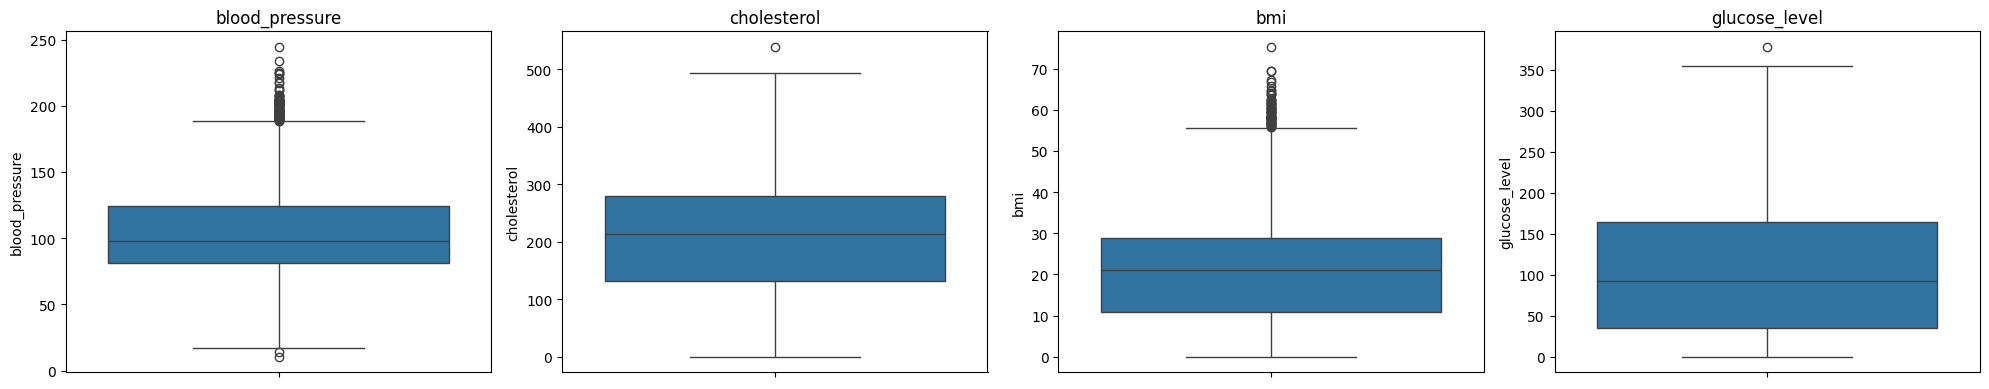

In [ ]:
num_cols = ['blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
for col in num_cols:
    df_clean[col] = df_clean[col].abs()   # детерминированно, утечки нет

# ВАЖНО: обрезку по медицинским границам и заполнение медианой
# делаем ПОСЛЕ train/test split (в следующей ячейке), чтобы медиана
# считалась только по train и не было утечки.

print("Мин после abs:", df_clean[num_cols].min().round(2).to_dict())
print("Макс после abs:", df_clean[num_cols].max().round(2).to_dict())

# Визуализация выбросов (как «до»)
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.3 Кодирование категориальных признаков

После удаления `treatment` остаётся только категориальный признак `gender`.

Применяем One-Hot Encoding с параметром `drop_first=True`. Для бинарного признака `gender` это создаёт один столбец `gender_Male`. Параметр `drop_first=True` помогает избежать «ловушки фиктивных переменных» и мультиколлинеарности.

In [ ]:
# После удаления treatment остаётся только gender
df_final = pd.get_dummies(df_clean, columns=['gender'], drop_first=True)

bool_cols = df_final.select_dtypes(include='bool').columns
df_final[bool_cols] = df_final[bool_cols].astype(int)

print(f"Размер датасета после кодирования: {df_final.shape}")
print("Столбцы:", df_final.columns.tolist())
display(df_final.head())

Размер датасета после кодирования: (10000, 7)
Столбцы: ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level', 'heart_disease', 'gender_Male']


,age,blood_pressure,cholesterol,bmi,glucose_level,heart_disease,gender_Male
0,21,138.068129,270.564349,36.101427,63.487954,1,0
1,44,100.383639,160.910030,14.330471,187.008977,0,0
2,22,145.618318,208.490251,20.277098,35.903576,0,0
3,19,152.577870,348.153738,62.712693,31.495166,1,0
4,64,111.793570,200.628925,14.468485,154.513129,1,0


### 3. Разделение данных и масштабирование

Сначала отделяем целевую переменную `y = heart_disease` от матрицы признаков `X`.

Далее:
1. Делим выборку на train/test в пропорции 80/20. Параметр `stratify=y` сохраняет соотношение классов в обеих частях.
2. В train и test независимо помечаем значения вне медицинских границ как `NaN`.
3. Медиану для заполнения считаем **только по train** и применяем её к train и test.
4. `StandardScaler` обучаем только на train, а к test применяем уже обученное преобразование.

One-hot признаки не масштабируем. Такая схема предотвращает утечку информации из тестовой выборки.

Train: (8000, 6), Test: (2000, 6)

Пример после стандартизации:


,age,blood_pressure,cholesterol,bmi,glucose_level,gender_Male
6311,-1.319112,0.384768,2.549787,1.027519,-0.355517,1
4910,-1.151849,-0.540626,0.046801,-1.074769,0.291450,1
1475,0.911060,0.061215,1.215421,0.656602,-0.735470,0
6082,0.911060,-0.637917,0.312452,-1.365400,-0.134029,0
6114,0.688043,-1.114682,-1.428993,-0.148375,1.651504,0


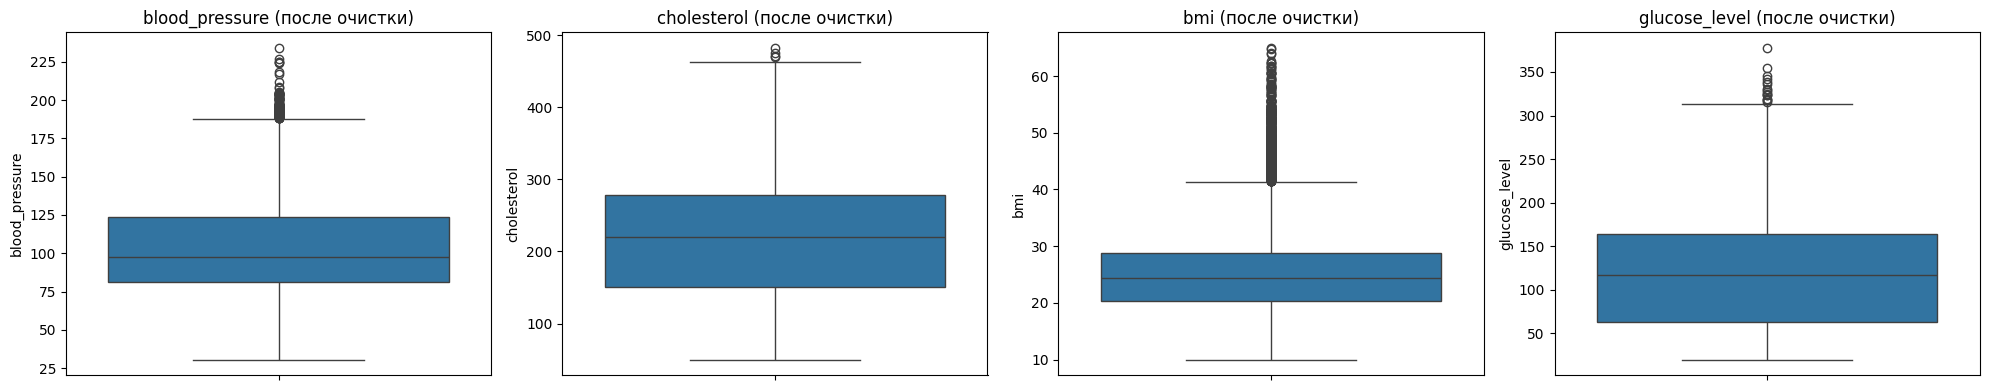

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_final.drop(columns=['heart_disease'])
y = df_final['heart_disease']

# 1. СНАЧАЛА делим на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# 2. Обрезка по мед. границам — можно делать на train и test независимо
X_train = X_train.copy()
X_test  = X_test.copy()
boundaries = {
    'blood_pressure': (30, 250),
    'cholesterol':    (50, 500),
    'bmi':            (10, 65),
    'glucose_level':  (20, 500),
}
for c, (lo, hi) in boundaries.items():
    X_train.loc[(X_train[c] < lo) | (X_train[c] > hi), c] = np.nan
    X_test.loc [(X_test[c]  < lo) | (X_test[c]  > hi), c] = np.nan

# 3. Медиана — ТОЛЬКО по train
for c in boundaries:
    med = X_train[c].median()
    X_train[c] = X_train[c].fillna(med)
    X_test[c]  = X_test[c].fillna(med)

# 4. Стандартизация — только непрерывные признаки, one-hot не трогаем
cont_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[cont_cols] = scaler.fit_transform(X_train[cont_cols])
X_test_scaled[cont_cols]  = scaler.transform(X_test[cont_cols])

print("\nПример после стандартизации:")
display(X_train_scaled.head())

# Визуализация уже очищенных train-признаков
fig, axes = plt.subplots(1, len(boundaries), figsize=(20, 4))
for ax, c in zip(axes, boundaries):
    sns.boxplot(y=X_train[c], ax=ax)
    ax.set_title(f"{c} (после очистки)")
plt.tight_layout()
plt.show()

### 4.1 Логистическая регрессия

В соответствии с четвертым пунктом задания, мы строим первую модель — Логистическую регрессию. Это базовый линейный алгоритм, который предсказывает вероятность принадлежности к классу 1 с помощью сигмоидной функции.

Для оценки качества мы рассчитываем метрики:
* `Accuracy` (общая точность),
* `Precision` (точность прогноза болезни),
* `Recall` (полнота — способность найти всех больных),
* `ROC-AUC` (качество разделения классов).

*В медицине `Recall` является ключевой метрикой, так как пропуск больного человека (False Negative) опаснее, чем ложная тревога.*

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# 1. Создаем модель (max_iter=1000 нужен, чтобы алгоритм точно сошелся)
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# 2. Обучаем модель на тренировочных данных
log_reg.fit(X_train_scaled, y_train)

# 3. Делаем предсказания на тестовой выборке
y_pred_log = log_reg.predict(X_test_scaled)

# 4. Считаем вероятности для ROC-AUC (вероятность класса 1)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# 5. Выводим метрики
print("--- Оценка Логистической Регрессии ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_log):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_log):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_log):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_log):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_log):.4f}")

print("\nМатрица ошибок (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred_log))

print("\nПолный отчет по классификации:")
print(classification_report(y_test, y_pred_log))

--- Оценка Логистической Регрессии ---
Accuracy:  0.7715
Precision: 0.7704
Recall:    0.7742
F1-score:  0.7723
ROC-AUC:   0.8500

Матрица ошибок (Confusion Matrix):
[[768 231]
 [226 775]]

Полный отчет по классификации:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77       999
           1       0.77      0.77      0.77      1001

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



### 4.2 Метод опорных векторов (SVM)

Вторая модель — SVM с радиальным ядром (`kernel='rbf'`). В отличие от логистической регрессии, SVM ищет гиперплоскость, которая максимально далеко отстоит от точек обоих классов (максимизирует зазор).

Благодаря нелинейному RBF-ядру, SVM способен улавливать сложные, нелинейные взаимосвязи между медицинскими показателями, которые линейная регрессия пропускает. Параметр `probability=True` позволяет нам получить вероятности для расчета ROC-AUC.

In [ ]:
from sklearn.svm import SVC

# 1. Создаем модель SVM (используем RBF ядро и включаем вероятности)
svm_model = SVC(kernel='rbf', random_state=42, probability=True)

# 2. Обучаем модель
# (может занять 10-30 секунд, так как SVM работает чуть медленнее логрегрессии)
svm_model.fit(X_train_scaled, y_train)

# 3. Делаем предсказания
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# 4. Выводим метрики
print("--- Оценка SVM (Метод опорных векторов) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_svm):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_svm):.4f}")

print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred_svm))

--- Оценка SVM (Метод опорных векторов) ---
Accuracy:  0.9020
Precision: 0.9162
Recall:    0.8851
F1-score:  0.9004
ROC-AUC:   0.9591

Матрица ошибок:
[[918  81]
 [115 886]]


### 4.3 Дерево решений (CART)

Третья модель — Дерево решений (CART). Оно работает по принципу последовательного разбиения данных по наиболее информативным признакам (например: "возраст > 50?", затем "давление > 140?").

Параметр `max_depth=5` ограничивает глубину дерева. Это необходимо, чтобы модель не переобучилась (не запомнила шум в обучающей выборке), а выучила общие закономерности. Деревья решений отлично работают с табличными данными и не требуют сложной предварительной подготовки, что делает их мощным инструментом.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# 1. Создаем модель дерева решений
# random_state для воспроизводимости, max_depth=5 ограничивает глубину, чтобы дерево не переобучилось
cart_model = DecisionTreeClassifier(random_state=42, max_depth=5)

# 2. Обучаем модель (деревья обучаются очень быстро)
cart_model.fit(X_train_scaled, y_train)

# 3. Делаем предсказания
y_pred_cart = cart_model.predict(X_test_scaled)
y_prob_cart = cart_model.predict_proba(X_test_scaled)[:, 1]

# 4. Выводим метрики
print("--- Оценка CART (Дерево решений) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_cart):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_cart):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_cart):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_cart):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_cart):.4f}")

print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred_cart))

--- Оценка CART (Дерево решений) ---
Accuracy:  0.9065
Precision: 0.9046
Recall:    0.9091
F1-score:  0.9068
ROC-AUC:   0.9598

Матрица ошибок:
[[903  96]
 [ 91 910]]


### 5. Оценка и сравнение качества моделей

Заключительный этап работы — сведение всех метрик в единую таблицу и визуальное сравнение алгоритмов.

Мы анализируем, какая модель показала наилучший баланс между точностью и полнотой (`F1-score`). Сводный график позволяет наглядно увидеть, что нелинейные модели (SVM и CART) справляются с задачей лучше, чем линейная логистическая регрессия, что говорит о сложной природе зависимостей в медицинских данных. В конце мы программно определяем модель-победителя.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
models = {
    'Logistic Regression': log_reg,
    'SVM (RBF)':           svm_model,
    'CART (Decision Tree)': cart_model,
}

for name, model in models.items():
    f1  = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='f1')
    auc = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='roc_auc')
    acc = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = {
        'CV Accuracy (mean±std)': f"{acc.mean():.4f} ± {acc.std():.4f}",
        'CV F1       (mean±std)': f"{f1.mean():.4f} ± {f1.std():.4f}",
        'CV ROC-AUC  (mean±std)': f"{auc.mean():.4f} ± {auc.std():.4f}",
    }

df_cv = pd.DataFrame(cv_results).T
print("=== 5-FOLD CROSS-VALIDATION (на train) ===")
display(df_cv)

=== 5-FOLD CROSS-VALIDATION (на train) ===


,CV Accuracy (mean±std),CV F1 (mean±std),CV ROC-AUC (mean±std)
Logistic Regression,0.7459 ± 0.0081,0.7443 ± 0.0096,0.8361 ± 0.0088
SVM (RBF),0.8825 ± 0.0076,0.8798 ± 0.0068,0.9536 ± 0.0056
CART (Decision Tree),0.8960 ± 0.0084,0.8947 ± 0.0080,0.9484 ± 0.0019


=== ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7715,0.7704,0.7742,0.7723,0.8500
SVM (RBF),0.9020,0.9162,0.8851,0.9004,0.9591
CART (Decision Tree),0.9065,0.9046,0.9091,0.9068,0.9598


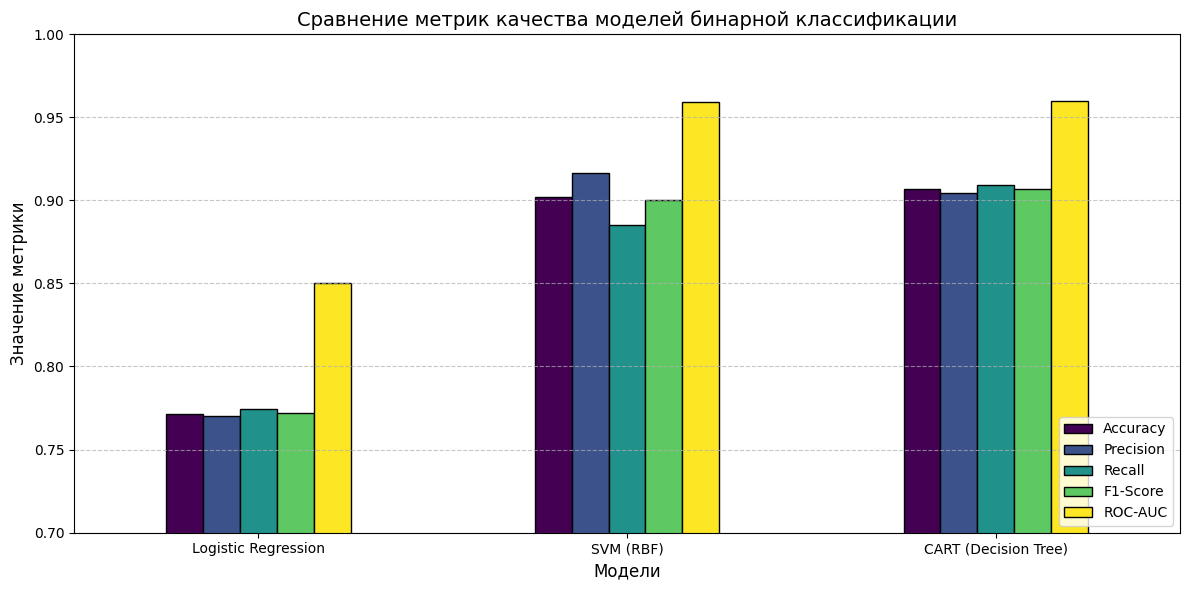


Лучшая модель по метрике F1-Score: CART (Decision Tree)


In [ ]:
import warnings
warnings.filterwarnings('ignore')

# 1. Собираем все метрики в один словарь
results = {
    'Model': ['Logistic Regression', 'SVM (RBF)', 'CART (Decision Tree)'],
    'Accuracy': [accuracy_score(y_test, y_pred_log), accuracy_score(y_test, y_pred_svm), accuracy_score(y_test, y_pred_cart)],
    'Precision': [precision_score(y_test, y_pred_log), precision_score(y_test, y_pred_svm), precision_score(y_test, y_pred_cart)],
    'Recall': [recall_score(y_test, y_pred_log), recall_score(y_test, y_pred_svm), recall_score(y_test, y_pred_cart)],
    'F1-Score': [f1_score(y_test, y_pred_log), f1_score(y_test, y_pred_svm), f1_score(y_test, y_pred_cart)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_log), roc_auc_score(y_test, y_prob_svm), roc_auc_score(y_test, y_prob_cart)]
}

# 2. Создаем DataFrame для красивого вывода
df_results = pd.DataFrame(results)
df_results.set_index('Model', inplace=True)

# Округляем до 4 знаков
df_results = df_results.round(4)
print("=== ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ===")
display(df_results)

# 3. Строим сравнительный график
df_results.plot(kind='bar', figsize=(12, 6), colormap='viridis', edgecolor='black')
plt.title('Сравнение метрик качества моделей бинарной классификации', fontsize=14)
plt.ylabel('Значение метрики', fontsize=12)
plt.xlabel('Модели', fontsize=12)
plt.ylim(0.7, 1.0) # Начинаем с 0.7, чтобы разница была заметнее
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 4. Определяем лучшую модель по F1-score
best_model = df_results['F1-Score'].idxmax()
print(f"\nЛучшая модель по метрике F1-Score: {best_model}")

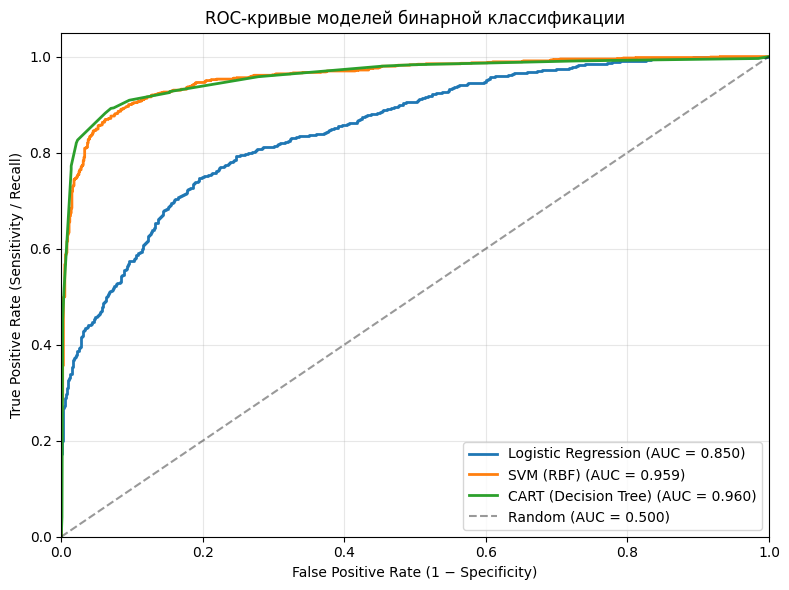

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, prob in [
    ('Logistic Regression', y_prob_log),
    ('SVM (RBF)',           y_prob_svm),
    ('CART (Decision Tree)', y_prob_cart),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC-кривые моделей бинарной классификации')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()